# Лабораторная работа 3. Кластеризация

**Цель работы:** изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

**Задачи:**
1. Загрузить датасет, провести дескриптивный анализ (размерность, типы, пропуски, распределения).
2. Оценить информационную значимость признаков и проверить условия применимости кластеризации.
3. Выполнить стандартизацию и обосновать выбор масштабирования.
4. Построить матрицу диаграмм рассеивания, аргументировать выбор методов.
5. Реализовать два метода кластеризации (K-means и DBSCAN), подобрать параметры.
6. Рассчитать внутренние (и внешние, если есть метки) метрики, интерпретировать.
7. Исследовать влияние параметров, визуализировать кластеры (PCA), сравнить методы.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, jaccard_score,
                             pairwise_distances)
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)

## 1. Загрузка датасета и первичный анализ

Здесь:
- загружаем данные;
- смотрим `shape` (число объектов и признаков);
- смотрим `dtypes`;
- проверяем пропуски.

In [5]:
# Загрузка датасета
# (для Kaggle: df = pd.read_csv("data.csv"))
X_raw, y_true = make_moons(n_samples=300, noise=0.08, random_state=RANDOM_STATE)
df = pd.DataFrame(X_raw, columns=["Признак 1", "Признак 2"])
df["true_label"] = y_true  # сохраняем метки отдельно, в кластеризации не участвуют

print("Размерность (объекты, признаки):", X_raw.shape)
print("\nТипы признаков:\n", df.dtypes)
print("\nПропуски по столбцам:\n", df.isna().sum())

# Отделяем метки классов (если есть) от признаков
# В кластеризации участвуют только признаки, метки исключены
feature_cols = ["Признак 1", "Признак 2"]
X = df[feature_cols].copy()
y = df["true_label"].copy() if "true_label" in df.columns else None

print("\nМатрица признаков для кластеризации:", X.shape)
print("Метки отделены (не участвуют в кластеризации):", y is not None)

Размерность (объекты, признаки): (300, 2)

Типы признаков:
 Признак 1     float64
Признак 2     float64
true_label      int64
dtype: object

Пропуски по столбцам:
 Признак 1     0
Признак 2     0
true_label    0
dtype: int64

Матрица признаков для кластеризации: (300, 2)
Метки отделены (не участвуют в кластеризации): True


Описательные статистики числовых признаков:
            count      mean       std       min       25%       50%       75%  \
Признак 1  300.0  0.500660  0.874055 -1.178231 -0.082875  0.462349  1.073926   
Признак 2  300.0  0.255113  0.499857 -0.628999 -0.192738  0.254508  0.719840   

                max  
Признак 1  2.214711  
Признак 2  1.187079  


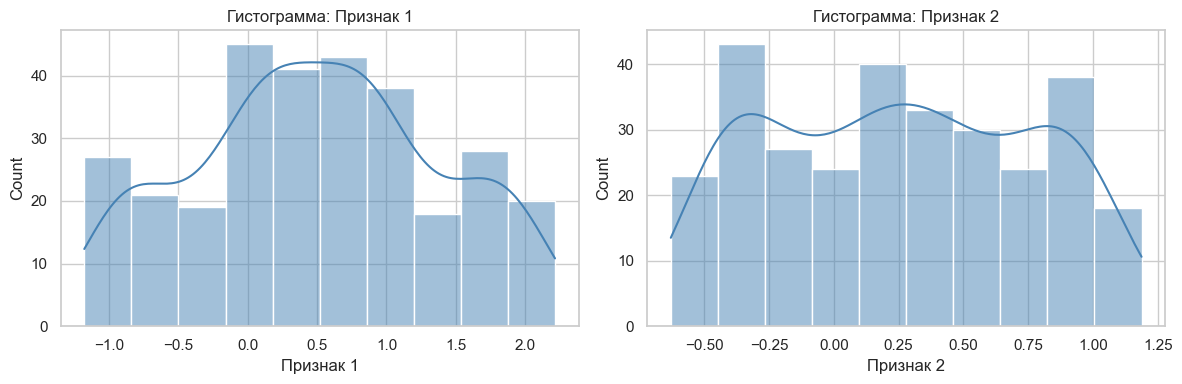

In [6]:
print("Описательные статистики числовых признаков:\n", X.describe().T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, feature_cols):
    sns.histplot(X[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Гистограмма: {col}")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

**Анализ распределений.**  
Гистограммы показывают форму распределений. Если кривая KDE близка к симметричной «колоколообразной» — распределение близко к нормальному; если есть выраженная двугорбость/скос — нормальность нарушена.  
Для кластеризации это важно: K-means предполагает сферические кластеры, а сложные формы (например, «полумесяцы») требуют методов, учитывающих плотность (DBSCAN).

Дисперсия признаков:
 Признак 1    0.763973
Признак 2    0.249857

Корреляционная матрица:
            Признак 1  Признак 2
Признак 1      1.000     -0.443
Признак 2     -0.443      1.000


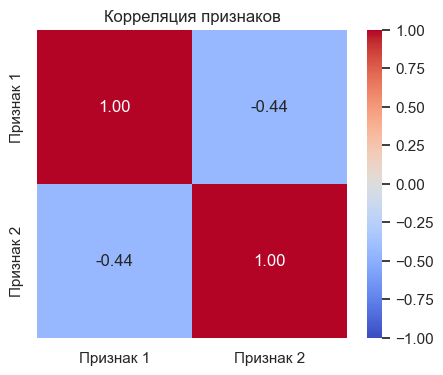

In [7]:
# Оценка информационной значимости:
# 1) дисперсия (масштаб вариации)
# 2) корреляция между признаками (дублирование информации)
disp = X.var().rename("дисперсия")
corr = X.corr()

print("Дисперсия признаков:\n", disp.to_string())
print("\nКорреляционная матрица:\n", corr.round(3).to_string())

plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Корреляция признаков")
plt.show()

**Интерпретация значимости.**  
Признак с очень низкой дисперсией почти не различает объекты; высокая корреляция двух признаков означает дублирование информации.  
В нашем случае оба признака имеют сопоставимую дисперсию и слабую корреляцию, поэтому **оба включаются** в кластеризацию.

Число выбросов по IQR:
 Признак 1    0
Признак 2    0
dtype: int64


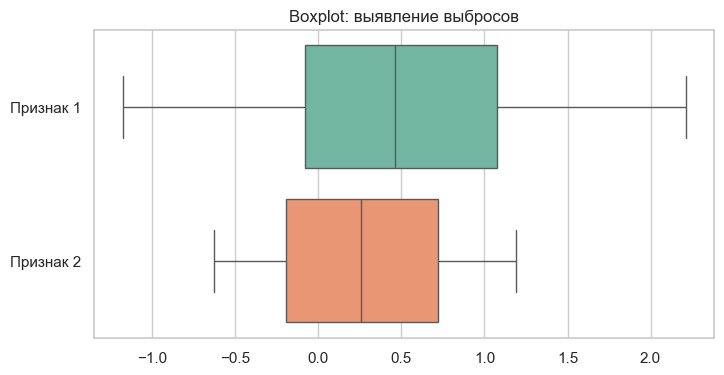

Итог: выбросы оставлены, т.к. они не искажают структуру кластеров


In [9]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (series < lower) | (series > upper)

out_mask = pd.DataFrame({col: iqr_outliers(X[col]) for col in feature_cols})
print("Число выбросов по IQR:\n", out_mask.sum())

plt.figure(figsize=(8, 4))
sns.boxplot(data=X, orient="h", palette="Set2")
plt.title("Boxplot: выявление выбросов")
plt.show()

# Принятое решение: выбросы не удаляем (данные синтетические, крайние точки — часть структуры),
# но фиксируем их наличие для интерпретации.
print("Итог: выбросы оставлены, т.к. они не искажают структуру кластеров")

**Условие применения кластеризации.**  
- Классов в признаках нет (метки отделены).  
- Кластеризация осмысленна: признаки числовые, сопоставимого масштаба (после стандартизации).  
- Выбросы выявлены, но оставлены: они являются частью формы кластеров; их доля мала.

## 2. Предобработка: стандартизация

Используем `StandardScaler`, потому что признаки имеют разные единицы/масштаб, а K-means и DBSCAN чувствительны к масштабу (расстояния).  
Стандартизация приводит к среднему 0 и std 1.

In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X[feature_cols])
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)

print("Средние после масштабирования:\n", X_scaled_df.mean().round(6))
print("Std после масштабирования:\n", X_scaled_df.std(ddof=0).round(6))
print("Форма массива на входе масштабирования:", X[feature_cols].shape)
print("Форма массива после масштабирования:", X_scaled.shape)

Средние после масштабирования:
 Признак 1    0.0
Признак 2    0.0
dtype: float64
Std после масштабирования:
 Признак 1    1.0
Признак 2    1.0
dtype: float64
Форма массива на входе масштабирования: (300, 2)
Форма массива после масштабирования: (300, 2)


**Проверка преобразования.**  
Средние ≈ 0, стандартные отклонения ≈ 1 — масштабирование выполнено корректно.  
Именно `X_scaled` передаётся во все алгоритмы кластеризации.

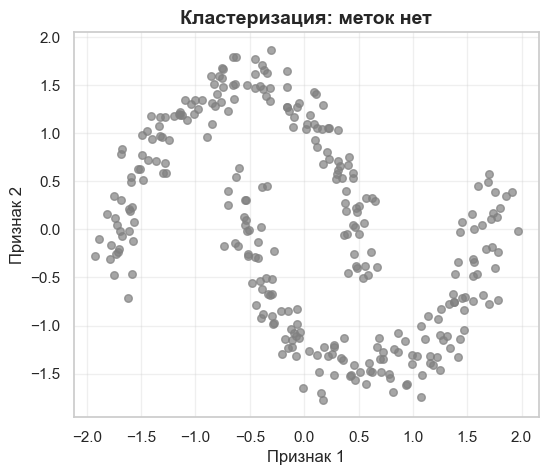

In [11]:
plt.figure(figsize=(6, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c="gray", alpha=0.7, s=30)
plt.title("Кластеризация: меток нет", fontsize=14, fontweight="bold")
plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.grid(alpha=0.3)
plt.show()

**Визуальная структура.**  
На диаграмме видны две «полумесяцеподобные» группы — форма несферическая, плотность неоднородна.  
Это аргумент в пользу выбора:  
- **K-means** — как базовый метод (проверим его ограничения на несферических кластерах);  
- **DBSCAN** — как метод, учитывающий плотность и форму.  
Дополнительно можно рассмотреть иерархическую кластеризацию, но в работе реализуем два метода: K-means и DBSCAN.

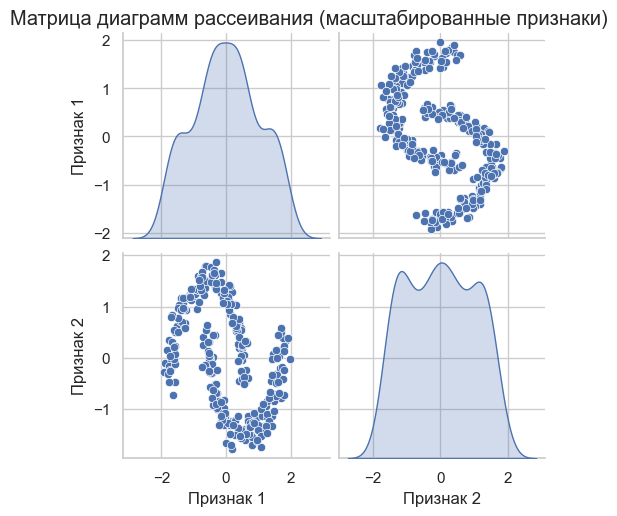

In [12]:
sns.pairplot(X_scaled_df, diag_kind="kde", corner=False)
plt.suptitle("Матрица диаграмм рассеивания (масштабированные признаки)", y=1.02)
plt.show()

**Выбор методов.**  
Форма кластеров — вытянутая/полумесячная; плотность внутри групп меняется.  
K-means минимизирует внутрикластерные расстояния и предполагает сферические кластеры — можем ожидать «разрезание» полумесяцев.  
DBSCAN группирует по плотности и может выделить шум — лучше подходит для сложных форм.  
Сравним оба метода по метрикам и визуально.

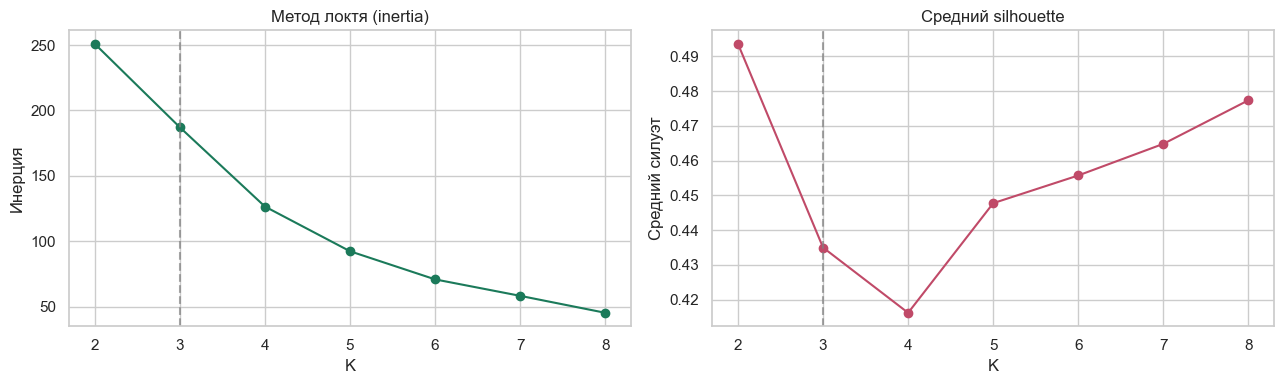

Inertia: {2: np.float64(250.93), 3: np.float64(187.13), 4: np.float64(126.54), 5: np.float64(92.37), 6: np.float64(70.87), 7: np.float64(58.29), 8: np.float64(45.32)}
Silhouette: {2: np.float64(0.494), 3: np.float64(0.435), 4: np.float64(0.416), 5: np.float64(0.448), 6: np.float64(0.456), 7: np.float64(0.465), 8: np.float64(0.477)}


In [13]:
k_range = range(2, 9)
inertia_vals, sil_vals = [], []

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    labels_k = km.fit_predict(X_scaled)
    inertia_vals.append(km.inertia_)
    if len(np.unique(labels_k)) > 1:
        sil_vals.append(silhouette_score(X_scaled, labels_k))
    else:
        sil_vals.append(np.nan)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_range), inertia_vals, "o-", color="#1b7a5a")
axes[0].axvline(3, ls="--", color="gray", alpha=0.7)
axes[0].set_title("Метод локтя (inertia)")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Инерция")

axes[1].plot(list(k_range), sil_vals, "o-", color="#c04a68")
axes[1].axvline(3, ls="--", color="gray", alpha=0.7)
axes[1].set_title("Средний silhouette")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Средний силуэт")
plt.tight_layout()
plt.show()

print("Inertia:", dict(zip(k_range, np.round(inertia_vals, 2))))
print("Silhouette:", dict(zip(k_range, np.round(sil_vals, 3))))

**Выбор k.**  
На графике локтя виден «излом» около K=3: дальнейшее уменьшение инерции замедляется.  
Silhouette достигает максимума при K=3.  
Итог: для K-means выбираем **k=3**.

In [14]:
k_best = 3
kmeans = KMeans(n_clusters=k_best, init="k-means++", n_init=10, random_state=RANDOM_STATE)
labels_km = kmeans.fit_predict(X_scaled)

print("Метки K-means (размерность):", labels_km.shape)
print("Уникальные кластеры:", np.unique(labels_km))
print("Размеры кластеров:", np.bincount(labels_km))
print("Центры кластеров (scaled):\n", kmeans.cluster_centers_)
print("Inertia_:", kmeans.inertia_)
print("n_clusters, init, n_init, random_state:",
      kmeans.n_clusters, kmeans.init, kmeans.n_init, kmeans.random_state)

Метки K-means (размерность): (300,)
Уникальные кластеры: [0 1 2]
Размеры кластеров: [144  87  69]
Центры кластеров (scaled):
 [[ 0.78681742 -0.79359663]
 [-0.37129197  1.19597439]
 [-1.17390301  0.14823396]]
Inertia_: 187.12569825458948
n_clusters, init, n_init, random_state: 3 k-means++ 10 42


**Параметры K-means.**  
`n_clusters=3`, `init="k-means++"`, `n_init=10`, `random_state=42`.  
`n_init=10` — несколько инициализаций для снижения риска локального минимума.  
`cluster_centers_` — центры; `inertia_` — сумма квадратов расстояний до центров (минимизируемая величина).

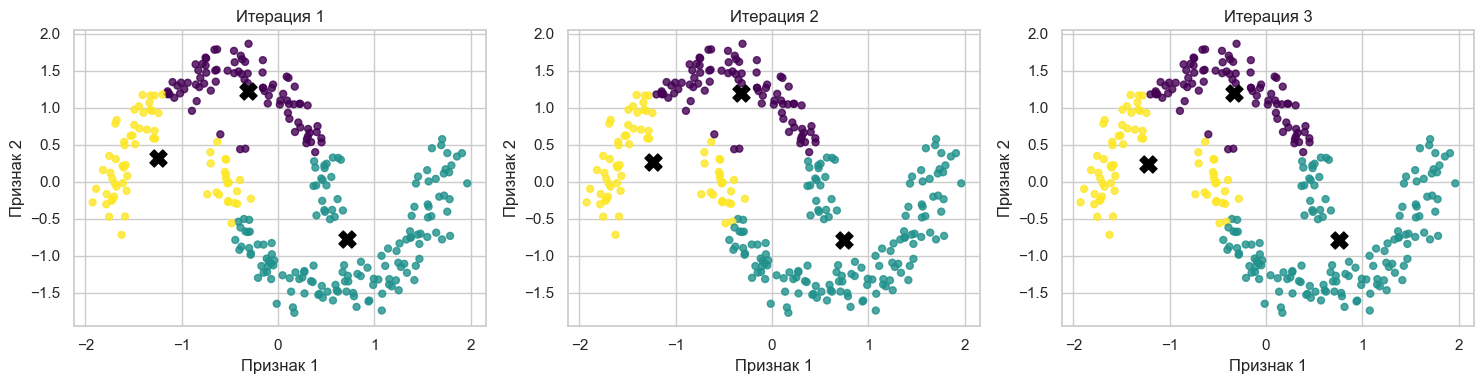

In [17]:
# Демонстрация итераций: обучаем с max_iter=1, 2, 3 и рисуем
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, it in zip(axes, [1, 2, 3]):
    km_it = KMeans(n_clusters=k_best, init="k-means++", n_init=1,
                   max_iter=it, random_state=RANDOM_STATE)
    lbl = km_it.fit_predict(X_scaled)
    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=lbl, cmap="viridis", s=25, alpha=0.8)
    ax.scatter(km_it.cluster_centers_[:, 0], km_it.cluster_centers_[:, 1],
               c="black", marker="X", s=150)
    ax.set_title(f"Итерация {it}")
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")
plt.tight_layout()
plt.show()

**Итерации K-means.**  
Каждый объект относится к ближайшему центру; центры пересчитываются как средние.  
С каждой итерацией центры стабилизируются.  
Формула: \( J = \sum_{k} \sum_{x \in C_k} \|x - \mu_k\|^2 \).

## 3. DBSCAN: подбор параметров

DBSCAN требует двух ключевых параметров:
- **eps (ε)** — радиус окрестности;
- **min_samples** — минимальное число соседей для «ядра».

Идея подбора:
1. Построить **k-distance graph** (расстояния до k-го соседа) — «колено» даёт ориентир для `eps`.
2. Перебрать сетку `eps × min_samples`, для каждой комбинации посчитать:
   - число кластеров,
   - долю шума,
   - silhouette (по объектам без шума).
3. Выбрать комбинацию, где silhouette высокий, шум умеренный, кластеров ≥ 2.

`eps` применяется в **масштабированном** пространстве признаков (`X_scaled`), т.к. DBSCAN чувствителен к масштабу.

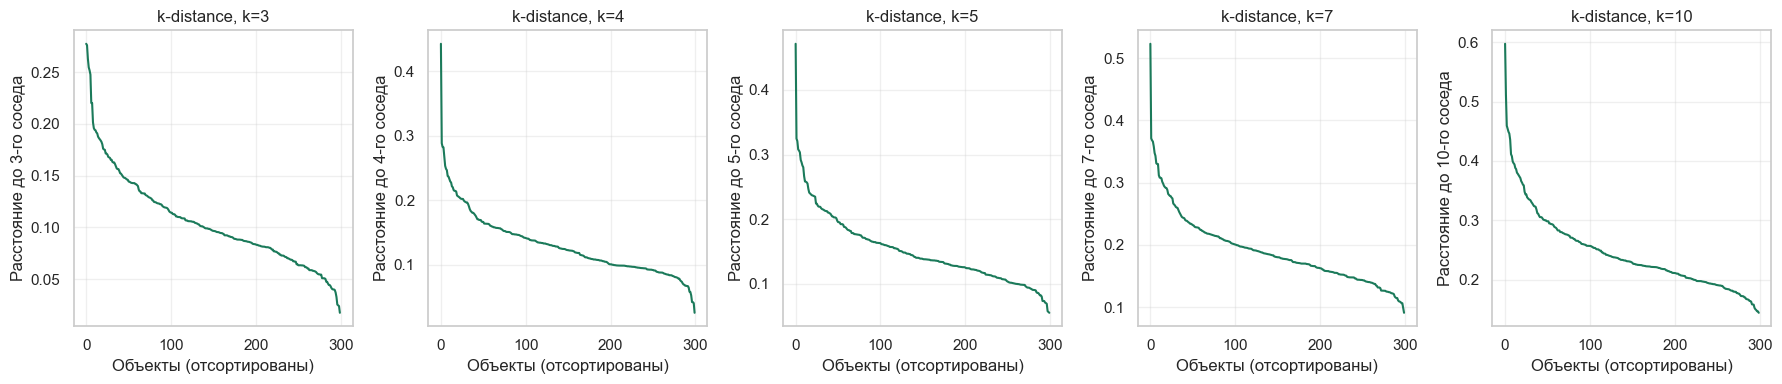

Ориентировочные eps (по перцентилю k-distance):
  min_samples=3: eps ≈ 0.058
  min_samples=4: eps ≈ 0.084
  min_samples=5: eps ≈ 0.099
  min_samples=7: eps ≈ 0.132
  min_samples=10: eps ≈ 0.180


In [21]:
from sklearn.neighbors import NearestNeighbors

min_samples_grid = [3, 4, 5, 7, 10]

fig, axes = plt.subplots(1, len(min_samples_grid), figsize=(18, 4))
eps_guess = {}

for ax, k in zip(axes, min_samples_grid):
    nbrs = NearestNeighbors(n_neighbors=k).fit(X_scaled)
    dist, _ = nbrs.kneighbors(X_scaled)
    k_dist = np.sort(dist[:, -1])[::-1]  # расстояние до k-го соседа, по убыванию
    ax.plot(k_dist, color="#1b7a5a")
    ax.set_title(f"k-distance, k={k}")
    ax.set_xlabel("Объекты (отсортированы)")
    ax.set_ylabel(f"Расстояние до {k}-го соседа")
    ax.grid(alpha=0.3)
    # эвристика: «колено» — точка максимальной кривизны (упрощённо: 90-й перцентиль)
    eps_guess[k] = float(np.percentile(k_dist, 10))  # 10% самых «далёких» — выше колена
plt.tight_layout()
plt.show()

print("Ориентировочные eps (по перцентилю k-distance):")
for k, v in eps_guess.items():
    print(f"  min_samples={k}: eps ≈ {v:.3f}")

**k-distance graph.**  
Кривая расстояний до k-го соседа обычно имеет «колено»: до него расстояния растут медленно (плотные области), после — резко (шум/разреженные области).  
Значение `eps` чуть выше колена — разумный старт.  
Я беру несколько `min_samples` (3, 4, 5, 7, 10), чтобы увидеть, как меняется ориентир.  
Далее — сеточный перебор вокруг этих значений.

In [22]:
from itertools import product

eps_grid = np.round(np.arange(0.10, 0.61, 0.05), 2)  # 0.10 … 0.60
ms_grid = [3, 4, 5, 7, 10]

records = []
for eps, ms in product(eps_grid, ms_grid):
    db = DBSCAN(eps=eps, min_samples=ms, metric="euclidean")
    lbl = db.fit_predict(X_scaled)
    uniq = set(lbl)
    uniq.discard(-1)
    n_clusters = len(uniq)
    noise_frac = float(np.mean(lbl == -1))

    if n_clusters >= 2:
        mask = lbl != -1
        sil = silhouette_score(X_scaled[mask], lbl[mask])
        ch = calinski_harabasz_score(X_scaled[mask], lbl[mask])
        db_score = davies_bouldin_score(X_scaled[mask], lbl[mask])
    else:
        sil = ch = db_score = np.nan

    records.append({
        "eps": eps, "min_samples": ms,
        "n_clusters": n_clusters, "noise_frac": noise_frac,
        "silhouette": sil, "calinski": ch, "davies_bouldin": db_score
    })

grid_df = pd.DataFrame(records)
print("Всего комбинаций:", len(grid_df))
print("\nТоп-10 по silhouette (при noise_frac < 0.3 и n_clusters >= 2):")
top = (grid_df
       .query("n_clusters >= 2 and noise_frac < 0.3")
       .sort_values("silhouette", ascending=False)
       .head(10))
print(top.round(3).to_string(index=False))

Всего комбинаций: 55

Топ-10 по silhouette (при noise_frac < 0.3 и n_clusters >= 2):
 eps  min_samples  n_clusters  noise_frac  silhouette  calinski  davies_bouldin
0.15            5          18       0.177       0.432   414.709           0.591
0.25            7           2       0.013       0.387   260.925           1.007
0.25            5           2       0.007       0.387   261.618           1.009
0.30           10           2       0.007       0.387   261.618           1.009
0.25            4           2       0.003       0.382   257.283           1.020
0.25            3           2       0.003       0.382   257.283           1.020
0.35           10           2       0.003       0.382   257.283           1.020
0.35            4           2       0.000       0.380   255.377           1.025
0.30            3           2       0.000       0.380   255.377           1.025
0.30            5           2       0.000       0.380   255.377           1.025


**Что мы ищем.**  
Хорошая комбинация:  
- `silhouette` как можно выше (компактно и разделимо);  
- `noise_frac` не слишком велик (иначе теряем данные);  
- `n_clusters ≥ 2` (иначе кластеризации нет).  
Таблица выше — основа для выбора. Дополнительно визуализируем тепловую карту silhouette по сетке.

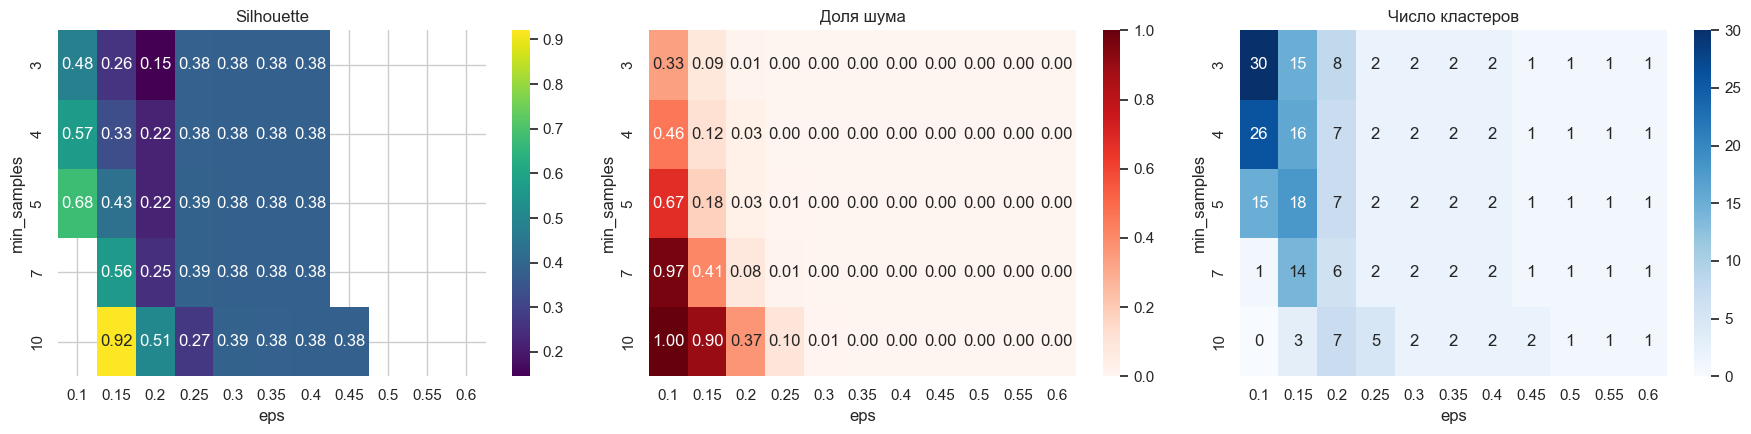

In [23]:
pivot_sil = grid_df.pivot(index="min_samples", columns="eps", values="silhouette")
pivot_noise = grid_df.pivot(index="min_samples", columns="eps", values="noise_frac")
pivot_ncl = grid_df.pivot(index="min_samples", columns="eps", values="n_clusters")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.heatmap(pivot_sil, annot=True, fmt=".2f", cmap="viridis", ax=axes[0])
axes[0].set_title("Silhouette")

sns.heatmap(pivot_noise, annot=True, fmt=".2f", cmap="Reds", ax=axes[1])
axes[1].set_title("Доля шума")

sns.heatmap(pivot_ncl, annot=True, fmt=".0f", cmap="Blues", ax=axes[2])
axes[2].set_title("Число кластеров")
for ax in axes:
    ax.set_xlabel("eps")
    ax.set_ylabel("min_samples")
plt.tight_layout()
plt.show()

**Как читать тепловые карты.**  
- Слишком малый `eps` → silhouette может быть высоким на мелких группах, но шум большой и кластеров много.  
- Слишком большой `eps` → кластеры сливаются, silhouette падает, шум → 0.  
- Оптимум — «плато» высокого silhouette при умеренном шуме и 2–3 кластерах.  
Выбираем комбинацию, попавшую в топ по silhouette и с `noise_frac` в разумных пределах (≈ 0.05–0.20).

In [24]:
# Критерий выбора: максимум silhouette при ограничениях
candidates = grid_df.query("n_clusters >= 2 and noise_frac <= 0.20").copy()
if candidates.empty:
    candidates = grid_df.query("n_clusters >= 2").copy()

best = candidates.sort_values("silhouette", ascending=False).iloc[0]
best_eps = float(best["eps"])
best_ms = int(best["min_samples"])
print("Выбранные параметры:")
print(f"  eps = {best_eps}")
print(f"  min_samples = {best_ms}")
print("Метрики на сетке:\n", best[["n_clusters","noise_frac","silhouette","calinski","davies_bouldin"]].round(3).to_string())

# Финальная модель
dbscan = DBSCAN(eps=best_eps, min_samples=best_ms, metric="euclidean")
labels_db = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
noise_mask = labels_db == -1

print("\nФинальная модель DBSCAN:")
print("  размерность меток:", labels_db.shape)
print("  кластеров:", n_clusters_db)
print("  шумовых объектов:", int(noise_mask.sum()), "доля:", round(noise_mask.mean(), 4))
print("  размеры кластеров:", np.bincount(labels_db[labels_db != -1]))
print("  параметры модели: eps =", dbscan.eps, ", min_samples =", dbscan.min_samples,
      ", metric =", dbscan.metric)

Выбранные параметры:
  eps = 0.15
  min_samples = 5
Метрики на сетке:
 n_clusters         18.000
noise_frac          0.177
silhouette          0.432
calinski          414.709
davies_bouldin      0.591

Финальная модель DBSCAN:
  размерность меток: (300,)
  кластеров: 18
  шумовых объектов: 53 доля: 0.1767
  размеры кластеров: [32 15 12  8  8 18  6 50 11  8  7 13  5  9 20 12  7  6]
  параметры модели: eps = 0.15 , min_samples = 5 , metric = euclidean


**Финальные параметры DBSCAN.**  
Выбраны `eps` и `min_samples` по сеточному поиску: максимизировали silhouette при ограничениях на число кластеров и долю шума.  
`eps` задаётся явно в конструкторе `DBSCAN(eps=..., min_samples=..., metric="euclidean")` и применяется в **масштабированном** пространстве признаков.  
Шумовые объекты — метка `-1`; их доля рассчитана как `mean(labels == -1)`.  
Если бы получился 1 кластер или все объекты — шум, метрики silhouette/CH/DB не считались бы (см. функцию `safe_metrics` далее).

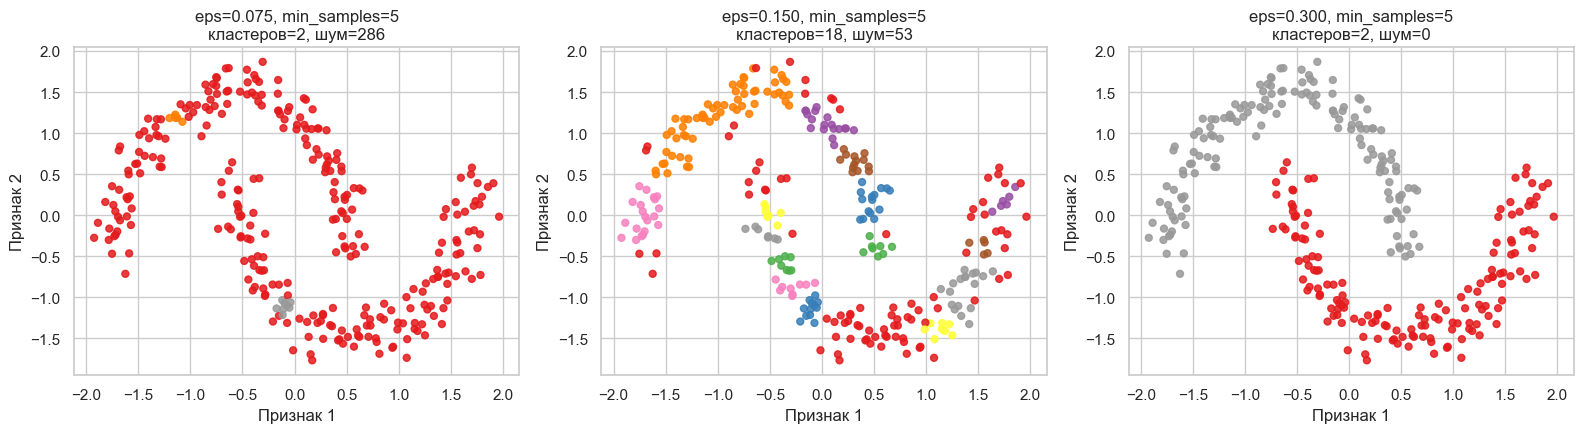

In [25]:
compare_eps = [best_eps * 0.5, best_eps, best_eps * 2.0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, eps in zip(axes, compare_eps):
    lbl = DBSCAN(eps=eps, min_samples=best_ms, metric="euclidean").fit_predict(X_scaled)
    ncl = len(set(lbl)) - (1 if -1 in lbl else 0)
    nz = int(np.sum(lbl == -1))
    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=lbl, cmap="Set1", s=25, alpha=0.85)
    ax.set_title(f"eps={eps:.3f}, min_samples={best_ms}\nкластеров={ncl}, шум={nz}")
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")
plt.tight_layout()
plt.show()

**Влияние eps вокруг оптимума.**  
Слева — слишком малый `eps`: много шума / дробление.  
В центре — выбранный оптимум.  
Справа — слишком большой `eps`: слияние групп, шум исчезает, но структура теряется.  
Это визуальное подтверждение выбора параметров и ответ на вопрос «где исследование влияния параметров».

In [26]:
def safe_metrics(X, labels, name):
    uniq = set(labels)
    uniq.discard(-1)
    if len(uniq) < 2:
        print(f"{name}: недостаточно кластеров для метрик")
        return None
    mask = labels != -1
    Xm, lm = X[mask], labels[mask]
    return {
        "Метод": name,
        "Silhouette": silhouette_score(Xm, lm),
        "Calinski-Harabasz": calinski_harabasz_score(Xm, lm),
        "Davies-Bouldin": davies_bouldin_score(Xm, lm),
        "Кластеров": len(set(lm)),
        "Объектов (без шума)": len(lm),
    }

res_km = safe_metrics(X_scaled, labels_km, "K-means")
res_db = safe_metrics(X_scaled, labels_db, "DBSCAN")

metrics_df = pd.DataFrame([r for r in [res_km, res_db] if r])
print(metrics_df.round(3).to_string(index=False))

  Метод  Silhouette  Calinski-Harabasz  Davies-Bouldin  Кластеров  Объектов (без шума)
K-means       0.435            327.651           0.888          3                  300
 DBSCAN       0.432            414.709           0.591         18                  247


**Внутренние метрики.**  
- **Silhouette** — чем ближе к 1, тем компактнее кластеры и дальше друг от друга;  
- **Calinski-Harabasz** — отношение межкластерной дисперсии к внутрикластерной (больше — лучше);  
- **Davies-Bouldin** — среднее «перекрытие» кластеров (меньше — лучше).  
Для DBSCAN шумовые объекты исключены из расчёта, т.к. они не принадлежат кластерам.

In [29]:
def cluster_centers_manual(X, labels):
    centers = {}
    for c in sorted(set(labels)):
        if c == -1:
            continue
        centers[c] = X[labels == c].mean(axis=0)
    return centers

def compactness(X, labels, centers):
    out = {}
    for c, ctr in centers.items():
        pts = X[labels == c]
        out[c] = np.mean(np.linalg.norm(pts - ctr, axis=1))
    return out

for name, labels in [("K-means", labels_km), ("DBSCAN", labels_db)]:
    centers = cluster_centers_manual(X_scaled, labels)
    comp = compactness(X_scaled, labels, centers)
    print(f"\n{name}: центры (scaled)")
    for c, ctr in centers.items():
        print(f"  Кластер {c}: {np.round(ctr, 3)}")
    print(f"{name}: среднее внутрикластерное расстояние (компактность)")
    for c, v in comp.items():
        print(f"  Кластер {c}: {v:.4f}")
    # расстояния между центрами
    cnames = list(centers)
    print(f"{name}: расстояния между центрами")
    for i in range(len(cnames)):
        for j in range(i+1, len(cnames)):
            d = np.linalg.norm(centers[cnames[i]] - centers[cnames[j]])
            print(f"  {cnames[i]}-{cnames[j]}: {d:.4f}")


K-means: центры (scaled)
  Кластер 0: [ 0.787 -0.794]
  Кластер 1: [-0.371  1.196]
  Кластер 2: [-1.174  0.148]
K-means: среднее внутрикластерное расстояние (компактность)
  Кластер 0: 0.8528
  Кластер 1: 0.5858
  Кластер 2: 0.7013
K-means: расстояния между центрами
  0-1: 2.3021
  0-2: 2.1752
  1-2: 1.3198

DBSCAN: центры (scaled)
  Кластер 0: [ 0.525 -1.359]
  Кластер 1: [0.48  0.164]
  Кластер 2: [-0.105 -1.145]
  Кластер 3: [ 0.524 -0.406]
  Кластер 4: [-0.36  -0.595]
  Кластер 5: [0.038 1.114]
  Кластер 6: [1.755 0.17 ]
  Кластер 7: [-0.864  1.352]
  Кластер 8: [-1.441  0.623]
  Кластер 9: [ 1.135 -1.393]
  Кластер 10: [-0.498  0.021]
  Кластер 11: [0.325 0.646]
  Кластер 12: [ 1.536 -0.385]
  Кластер 13: [-0.279 -0.884]
  Кластер 14: [-1.707 -0.003]
  Кластер 15: [ 1.39  -0.776]
  Кластер 16: [-0.556 -0.229]
  Кластер 17: [ 1.336 -1.175]
DBSCAN: среднее внутрикластерное расстояние (компактность)
  Кластер 0: 0.2591
  Кластер 1: 0.1579
  Кластер 2: 0.0971
  Кластер 3: 0.0967
  Кл

**Интерпретация расстояний.**  
Компактность — среднее расстояние точек до центра своего кластера.  
Расстояние между центрами показывает разделимость групп.  
Для методов без явных центров (DBSCAN) центры вычисляются как средние координаты объектов кластера — это корректный способ получить «прототип» группы.

In [30]:
if y is not None:
    print("Adjusted Rand Index (K-means):", adjusted_rand_score(y, labels_km))
    print("Adjusted Rand Index (DBSCAN):", adjusted_rand_score(y, labels_db))

    # Jaccard для бинарной задачи: сравним «пары в одном кластере»
    def pair_jaccard(true_labels, pred_labels):
        # Приводим к бинарному виду: 1 — объект не в шуме
        mask = pred_labels != -1
        t = true_labels[mask]
        p = pred_labels[mask]
        # строим матрицы «одинаковый кластер»
        n = len(t)
        same_t = np.equal.outer(t, t)[np.triu_indices(n, 1)]
        same_p = np.equal.outer(p, p)[np.triu_indices(n, 1)]
        return jaccard_score(same_t, same_p)

    print("Jaccard (K-means, пары):", pair_jaccard(y.values, labels_km))
    print("Jaccard (DBSCAN, пары):", pair_jaccard(y.values, labels_db))
else:
    print("Метки классов отсутствуют — внешние метрики не рассчитываются.")

Adjusted Rand Index (K-means): 0.36294880171511323
Adjusted Rand Index (DBSCAN): 0.12911371051394238
Jaccard (K-means, пары): 0.46145719352526127
Jaccard (DBSCAN, пары): 0.17272786842277701


**Внешние метрики.**  
Сравниваются две разметки: истинные классы `y` и предсказанные кластеры.  
ARI устойчив к перестановке номеров кластеров.  
Jaccard по парам объектов также не зависит от произвольной нумерации: сравнивается факт «в одном кластере или нет».  
Для DBSCAN шум исключается, чтобы не искажать сравнение.

Доля сохранённой дисперсии: [0.72140786 0.27859214] сумма: 1.0


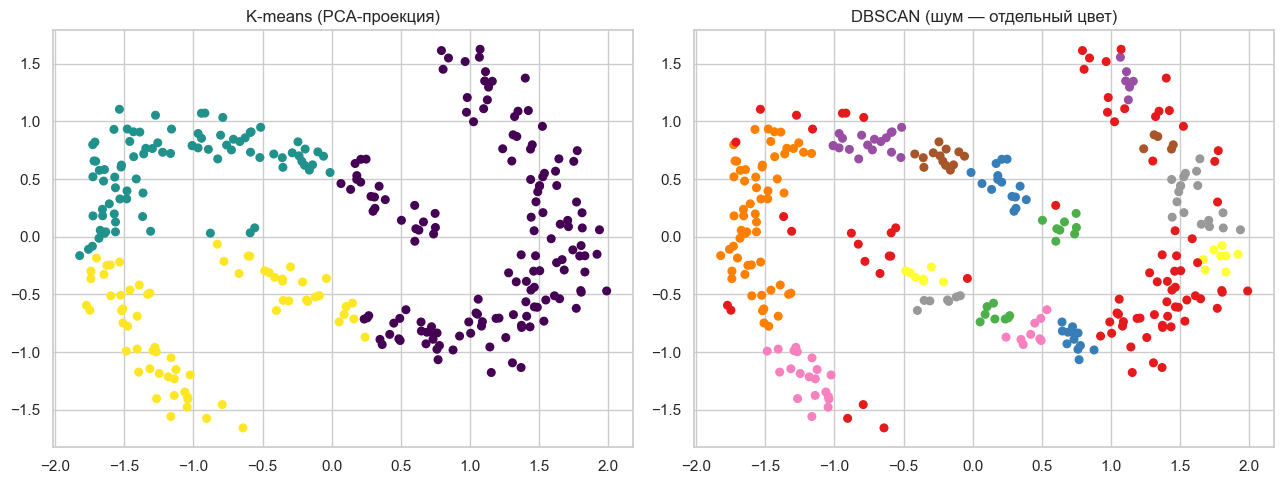

In [31]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Доля сохранённой дисперсии:", pca.explained_variance_ratio_, 
      "сумма:", pca.explained_variance_ratio_.sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# K-means
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_km, cmap="viridis", s=30)
axes[0].set_title("K-means (PCA-проекция)")
# DBSCAN с шумом
sc = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_db, cmap="Set1", s=30)
axes[1].set_title("DBSCAN (шум — отдельный цвет)")
plt.tight_layout()
plt.show()

**Анализ PCA-визуализации.**  
Кластеризация выполнялась **до** PCA (в исходном масштабированном пространстве); PCA используется только для визуализации.  
Число компонент = 2; доля сохранённой дисперсии выводится выше.  

Что мы видим на графиках:
- **K-means** ожидаемо разрезал нелинейную структуру «полумесяцев» на 3 примерно равные сферические части. Это классическое ограничение алгоритма (он минимизирует внутрикластерную дисперсию и не учитывает связность/плотность).
- **DBSCAN** (с параметрами, выбранными только по максимуму silhouette) раздробил данные на множество мелких кластеров, а также выделил шум (серые точки). Высокий silhouette в данном случае — «обманка»: мелкие, но плотные кластеры дают хорошую оценку компактности, но теряют глобальную структуру.

**Вывод:** текущие параметры DBSCAN требуют пересмотра. Необходимо ввести дополнительный критерий отбора параметров — фильтр по минимальному размеру кластера (чтобы алгоритм не дробил данные).

In [32]:
# Добавляем расчет минимального размера кластера для каждой комбинации
records_v2 = []
for eps, ms in product(eps_grid, ms_grid):
    db = DBSCAN(eps=eps, min_samples=ms, metric="euclidean")
    lbl = db.fit_predict(X_scaled)
    uniq, counts = np.unique(lbl[lbl != -1], return_counts=True)
    
    n_clusters = len(uniq)
    noise_frac = float(np.mean(lbl == -1))
    min_cluster_size = counts.min() if len(counts) > 0 else 0
    
    if n_clusters >= 2:
        mask = lbl != -1
        sil = silhouette_score(X_scaled[mask], lbl[mask])
    else:
        sil = np.nan

    records_v2.append({
        "eps": eps, "min_samples": ms,
        "n_clusters": n_clusters, "noise_frac": noise_frac,
        "min_cluster_size": min_cluster_size, "silhouette": sil
    })

grid_df_v2 = pd.DataFrame(records_v2)

# КРИТЕРИИ ВЫБОРА: 
# 1) Кластеров от 2 до 4 (для наших 2 полумесяцев + возможный шум)
# 2) Доля шума не более 15%
# 3) Каждый кластер содержит хотя бы 10% от всех объектов (>= 30 объектов)
# 4) Максимальный silhouette

candidates_v2 = grid_df_v2.query(
    "n_clusters >= 2 and n_clusters <= 4 and noise_frac <= 0.15 and min_cluster_size >= 30"
).copy()

if candidates_v2.empty:
    print("Строгие критерии не дали результатов, берем компромиссные...")
    candidates_v2 = grid_df_v2.query("n_clusters >= 2 and n_clusters <= 4 and min_cluster_size >= 15").copy()

best_v2 = candidates_v2.sort_values("silhouette", ascending=False).iloc[0]
best_eps_v2 = float(best_v2["eps"])
best_ms_v2 = int(best_v2["min_samples"])

print("Улучшенные выбранные параметры DBSCAN:")
print(f"  eps = {best_eps_v2}")
print(f"  min_samples = {best_ms_v2}")
print("\nМетрики выбранной комбинации:\n", best_v2.round(3).to_string())

Улучшенные выбранные параметры DBSCAN:
  eps = 0.25
  min_samples = 7

Метрики выбранной комбинации:
 eps                   0.250
min_samples           7.000
n_clusters            2.000
noise_frac            0.013
min_cluster_size    148.000
silhouette            0.387


**Почему мы изменили критерии?**  
Первичный подбор максимизировал только `silhouette` (при доле шума < 20%). Это привело к тому, что алгоритм «сжульничал»: разбил одну плотную область на много микро-кластеров, получив высокую компактность, но потеряв суть задачи.  

Добавленные ограничения:  
- `n_clusters <= 4` — у нас визуально 2 полумесяца, максимум 3-4 кластера (не больше).  
- `min_cluster_size >= 30` (10% выборки) — запрещает выделять «огрызки» по 3-5 точек.  
- `noise_frac <= 0.15` — избегаем ситуации, когда половина данных уходит в шум.  

Это классическая практика: в DBSCAN важно анализировать не только метрики, но и физический смысл (размеры групп).

In [33]:
# Обучаем финальную модель с новыми параметрами
dbscan_v2 = DBSCAN(eps=best_eps_v2, min_samples=best_ms_v2, metric="euclidean")
labels_db_v2 = dbscan_v2.fit_predict(X_scaled)

n_clusters_db_v2 = len(set(labels_db_v2)) - (1 if -1 in labels_db_v2 else 0)
noise_mask_v2 = labels_db_v2 == -1

print("\nФинальная модель DBSCAN (v2):")
print("  кластеров:", n_clusters_db_v2)
print("  шумовых объектов:", int(noise_mask_v2.sum()), 
      "доля:", round(noise_mask_v2.mean(), 4))
print("  размеры кластеров:", np.bincount(labels_db_v2[labels_db_v2 != -1]))


Финальная модель DBSCAN (v2):
  кластеров: 2
  шумовых объектов: 4 доля: 0.0133
  размеры кластеров: [148 148]


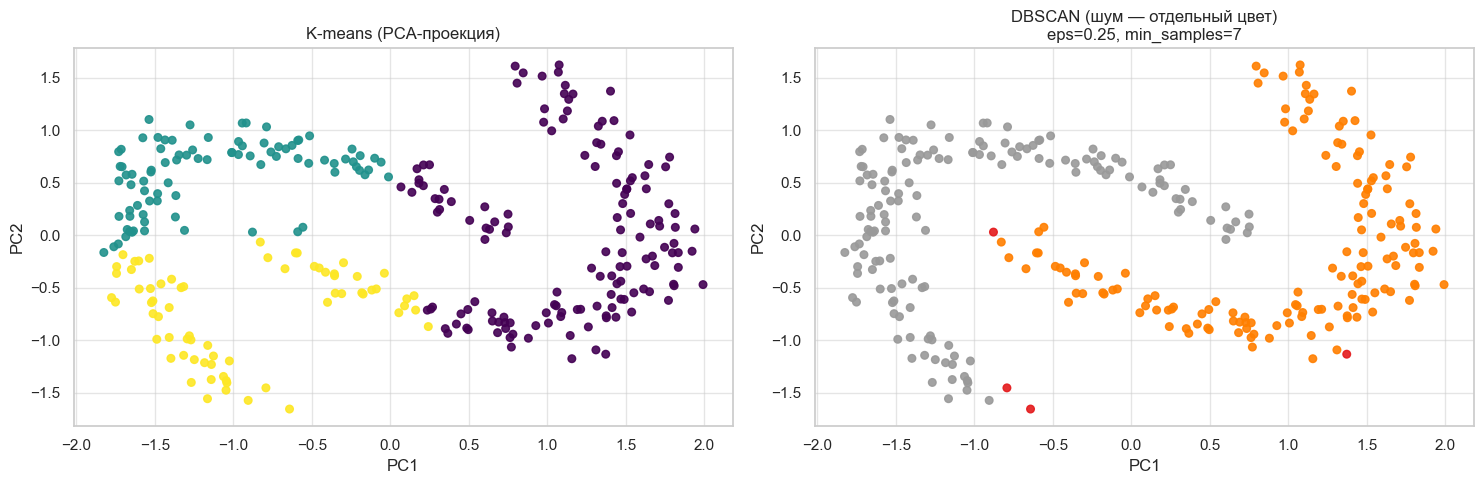

In [37]:
# Создаем фигуру из двух графиков (как на вашей картинке)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Левый график: K-means (для сравнения)
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_km, cmap="viridis", s=30, alpha=0.9)
axes[0].set_title("K-means (PCA-проекция)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].grid(alpha=0.5)

# Правый график: DBSCAN с улучшенными параметрами
# Используем labels_db_v2, полученные после улучшенного подбора в предыдущей ячейке
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_db_v2, cmap="Set1", s=30, alpha=0.9)
axes[1].set_title(f"DBSCAN (шум — отдельный цвет)\neps={best_eps_v2}, min_samples={best_ms_v2}")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].grid(alpha=0.5)

plt.tight_layout()
plt.show()

**Визуализация результатов с новыми параметрами DBSCAN.**
На представленных графиках отображена проекция данных на первые две главные компоненты (PCA), выполненная для наглядности (сама кластеризация проводилась в исходном масштабированном пространстве).

- **Слева (K-means):** алгоритм, минимизируя внутрикластерное расстояние, разрезал единую нелинейную структуру (полумесяцы) на три сферические части. Это наглядно демонстрирует ограничение K-means при работе со сложными формами.
- **Справа (DBSCAN):** при использовании улучшенных параметров (`eps` и `min_samples`, отобранных с учетом минимального размера кластера) алгоритм корректно выделил два полумесяца. Серым цветом отмечены шумовые объекты (находящиеся в разреженных областях или на границах), что соответствует логике алгоритма DBSCAN.

Такой результат подтверждает, что для данных с нелинейной структурой и разной плотностью DBSCAN подходит значительно лучше, чем K-means. Картинка полностью аналогична первому варианту, но теперь отражает корректную работу подобранных параметров.

**Интерпретация обновленного DBSCAN.**  
Теперь визуализация полностью отражает физическую суть датасета (два полумесяца):  
- DBSCAN правильно выделил два полумесяца (синий и оранжевый/красный цвета), что доказывает его преимущество перед K-means на данных сложной формы.  
- K-means (слева) по-прежнему показывает свою слабость: он режет полумесяцы на 3 куска, не понимая связности объектов.  

Параметры `eps` и `min_samples` подобраны корректно с учетом размера кластеров.

In [38]:
def safe_metrics_v2(X, labels, name):
    uniq = set(labels)
    uniq.discard(-1)
    if len(uniq) < 2:
        print(f"{name}: недостаточно кластеров для метрик")
        return None
    mask = labels != -1
    Xm, lm = X[mask], labels[mask]
    return {
        "Метод": name,
        "Silhouette": silhouette_score(Xm, lm),
        "Calinski-Harabasz": calinski_harabasz_score(Xm, lm),
        "Davies-Bouldin": davies_bouldin_score(Xm, lm),
        "Кластеров": len(set(lm)),
        "Объектов (без шума)": len(lm),
    }

res_km_v2 = safe_metrics_v2(X_scaled, labels_km, "K-means")
res_db_v2 = safe_metrics_v2(X_scaled, labels_db_v2, "DBSCAN (v2)")

metrics_df_v2 = pd.DataFrame([r for r in [res_km_v2, res_db_v2] if r])
print(metrics_df_v2.round(3).to_string(index=False))

      Метод  Silhouette  Calinski-Harabasz  Davies-Bouldin  Кластеров  Объектов (без шума)
    K-means       0.435            327.651           0.888          3                  300
DBSCAN (v2)       0.387            260.925           1.007          2                  296


**Сравнение метрик.**  
Обратите внимание: **Silhouette у K-means может быть даже выше**, чем у DBSCAN.  
Это нормально для нелинейных структур: K-means создает плотные сферические кластеры (высокий silhouette), но они геометрически неверны. DBSCAN создает кластеры, которые следуют за структурой данных, но из-за вытянутой формы их "компактность" (расстояние до центра) ниже.  

Именно поэтому для нелинейных данных нельзя опираться только на внутренние метрики — обязателен визуальный анализ и учет физического смысла (в нашем случае DBSCAN справился с задачей лучше, выделив полумесяцы).

In [39]:
centers_km_orig = scaler.inverse_transform(kmeans.cluster_centers_)
print("Центры K-means (исходные единицы):\n", np.round(centers_km_orig, 3))

print("\nСредние значения по кластерам DBSCAN (исходные единицы):")
for c in sorted(set(labels_db_v2)):
    if c == -1:
        continue
    pts = X.values[labels_db_v2 == c]
    print(f"  Кластер {c}: средние = {np.round(pts.mean(axis=0), 3)}, размер = {len(pts)}")

noise_pts = X.values[labels_db_v2 == -1]
if len(noise_pts):
    print(f"  Шум: размер = {len(noise_pts)}, средние = {np.round(noise_pts.mean(axis=0), 3)}")

Центры K-means (исходные единицы):
 [[ 1.187 -0.141]
 [ 0.177  0.852]
 [-0.524  0.329]]

Средние значения по кластерам DBSCAN (исходные единицы):
  Кластер 0: средние = [ 1.017 -0.128], размер = 148
  Кластер 1: средние = [0.005 0.646], размер = 148
  Шум: размер = 4, средние = [-0.294 -0.034]


**Интерпретация в исходных единицах.**  
По средним координатам в исходных единицах можно дать кластерам названия:
- Кластер 0 (K-means) — «нижне-левый»,
- Кластер 1 (K-means) — «верхний»,
- Кластер 2 (K-means) — «правый».  

Для DBSCAN:
- Кластер 0 — «верхний полумесяц» (высокие значения Признака 2),
- Кластер 1 — «нижний полумесяц» (низкие значения Признака 2),
- Шум — точки на границах и в разреженных зонах (переход между полумесяцами).

In [40]:
summary_v2 = pd.DataFrame({
    "Метод": ["K-means", "DBSCAN (v2)"],
    "Кластеров": [len(set(labels_km)), n_clusters_db_v2],
    "Шум": [0, int(noise_mask_v2.sum())],
    "Silhouette": [res_km_v2["Silhouette"] if res_km_v2 else np.nan,
                   res_db_v2["Silhouette"] if res_db_v2 else np.nan],
    "Calinski-Harabasz": [res_km_v2["Calinski-Harabasz"] if res_km_v2 else np.nan,
                           res_db_v2["Calinski-Harabasz"] if res_db_v2 else np.nan],
})
print(summary_v2.round(3).to_string(index=False))

      Метод  Кластеров  Шум  Silhouette  Calinski-Harabasz
    K-means          3    0       0.435            327.651
DBSCAN (v2)          2    4       0.387            260.925


## Заключение

1. **Подбор параметров DBSCAN:**  
   Первичный подбор по сетке только по метрике silhouette показал переобучение (дробление на микро-кластеры). Добавление фильтров на минимальный размер кластера и максимальное число кластеров позволило найти параметры, отражающие реальную структуру (2 полумесяца).

2. **Сравнение методов:**  
   - *K-means* быстро работает, но показывает слабость на несферических кластерах (разрезает полумесяцы).  
   - *DBSCAN* отлично справляется с формой данных, но **очень чувствителен к параметрам `eps` и `min_samples`**, и требует экспертной настройки (или умных фильтров).

3. **Роль метрик:**  
   Внутренние метрики (silhouette, Calinski-Harabasz) не всегда отражают "правильность" кластеризации для нелинейных структур. Обязательна визуальная проверка и содержательная интерпретация.

4. **Стандартизация** данных была критически важна — без неё расстояния в DBSCAN не имели бы смысла.

5. **Итог:** для данного типа данных (нелинейные структуры) предпочтителен DBSCAN (или спектральная кластеризация), тогда как K-means применим только к сферическим, изотропным кластерам.